# DINOv3 feature space of the full GrandTour dataset

Frozen `facebook/dinov3-vitb16-pretrain-lvd1689m` (via HF Hub), mean-pooled
patch tokens, one feature vector per subsampled frame (`extract_features.py`,
200 evenly-spaced frames/mission, 26 missions). Points are colored by which
split/tier they belong to (train / held-out ID / near-OOD forest / near-OOD
gravel / far-OOD snow / far-OOD ARC), matching `grandtour.yaml`'s
`TRAIN_MISSIONS` / `VALID_MISSIONS` / `NEAR_OOD_MISSIONS` / `FAR_OOD_MISSIONS`.

Both PCA and t-SNE are shown, in 2D and 3D, static (saved as PDF for the
thesis) and interactive (Plotly, rotatable / zoomable, mission on hover).

In [1]:
import pathlib

import matplotlib
import numpy as np
import plotly.graph_objects as go
from matplotlib import pyplot as plt
from scipy.spatial import ConvexHull
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score


def find_repo_root(start="."):
    p = pathlib.Path(start).resolve()
    while not (p / "AGENTS.md").exists():
        p = p.parent
    return p


REPO_ROOT = find_repo_root()
EXP_DIR = REPO_ROOT / "side_experiments/dino_feature_space"
OUT_DIR = EXP_DIR / "output"
OUT_DIR.mkdir(exist_ok=True)


def add_tier_hulls(fig, points, tier, order, label, color, opacity=0.12):
    """Overlay a translucent 3D convex-hull mesh per tier, so each set's extent
    in the embedding reads as a solid region instead of just a point cloud."""
    for t in order:
        pts = points[tier == t]
        if len(pts) < 4:
            continue
        hull = ConvexHull(pts)
        fig.add_trace(go.Mesh3d(
            x=pts[:, 0], y=pts[:, 1], z=pts[:, 2],
            i=hull.simplices[:, 0], j=hull.simplices[:, 1], k=hull.simplices[:, 2],
            color=color[t], opacity=opacity, name=f"{label[t]} (hull)",
            showlegend=False, hoverinfo="skip", flatshading=True,
        ))
    return fig

In [2]:
d = np.load(OUT_DIR / "features.npz")
X, mission, tier = d["features"], d["mission"], d["tier"]
print(f"{len(X)} frames, {X.shape[1]}-d features, model {d['model']}")

TIER_ORDER = ["train", "id_heldout", "near_forest", "near_gravel", "far_snow", "far_arc"]
TIER_LABEL = {
    "train": "ID (train)",
    "id_heldout": "ID (held-out)",
    "near_forest": "near-OOD (forest)",
    "near_gravel": "near-OOD (gravel)",
    "far_snow": "far-OOD (snow)",
    "far_arc": "far-OOD (arctic/industrial)",
}
TIER_COLOR = {
    "train": "#1f77b4",
    "id_heldout": "#17becf",
    "near_forest": "#2ca02c",
    "near_gravel": "#bcbd22",
    "far_snow": "#9467bd",
    "far_arc": "#d62728",
}
for t in TIER_ORDER:
    m = tier == t
    print(f"  {t:<12} {m.sum():>5}  missions: {sorted(set(mission[m]))}")

Xs = (X - X.mean(0)) / (X.std(0) + 1e-8)

5200 frames, 768-d features, model facebook/dinov3-vitb16-pretrain-lvd1689m
  train         2000  missions: [np.str_('ALB-1'), np.str_('ALB-2'), np.str_('CYN-1'), np.str_('HIL-1'), np.str_('HOEB-1'), np.str_('KAEB-2'), np.str_('KAEB-3'), np.str_('LMB-1'), np.str_('RIV-1'), np.str_('TRIM-1')]
  id_heldout     800  missions: [np.str_('ALB-3'), np.str_('CYN-2'), np.str_('HOEB-2'), np.str_('LMB-2')]
  near_forest    400  missions: [np.str_('KAEB-1'), np.str_('ROOT-1')]
  near_gravel    600  missions: [np.str_('EIG-1'), np.str_('EIG-2'), np.str_('PIL-2')]
  far_snow       600  missions: [np.str_('SNOW-1'), np.str_('SNOW-2'), np.str_('SNOW-3')]
  far_arc        800  missions: [np.str_('ARC-1'), np.str_('ARC-2'), np.str_('ARC-3'), np.str_('ARC-4')]


## Raw-feature separability (projection-independent)

Silhouette score of the 768-d standardized features w.r.t. tier labels, before
any 2D/3D projection distorts anything. This is the ground truth that the PCA
and t-SNE plots below are trying to depict; use it to judge which projection is
more faithful, not just prettier.

In [3]:
sil_raw = silhouette_score(Xs, tier)
print(f"silhouette(raw 768-d, tier) = {sil_raw:.3f}")
print("(-1..1; >0 means tiers form real neighborhoods in feature space, not just in the 2D/3D picture)")

silhouette(raw 768-d, tier) = 0.088
(-1..1; >0 means tiers form real neighborhoods in feature space, not just in the 2D/3D picture)


## 2-component PCA

In [4]:
pca2 = PCA(2).fit(Xs)
p2 = pca2.transform(Xs)
print(f"explained variance ratio: {pca2.explained_variance_ratio_}")
sil_pca2 = silhouette_score(p2, tier)
print(f"silhouette(PCA-2d, tier) = {sil_pca2:.3f}")

explained variance ratio: [0.21460477 0.10567474]


silhouette(PCA-2d, tier) = 0.197


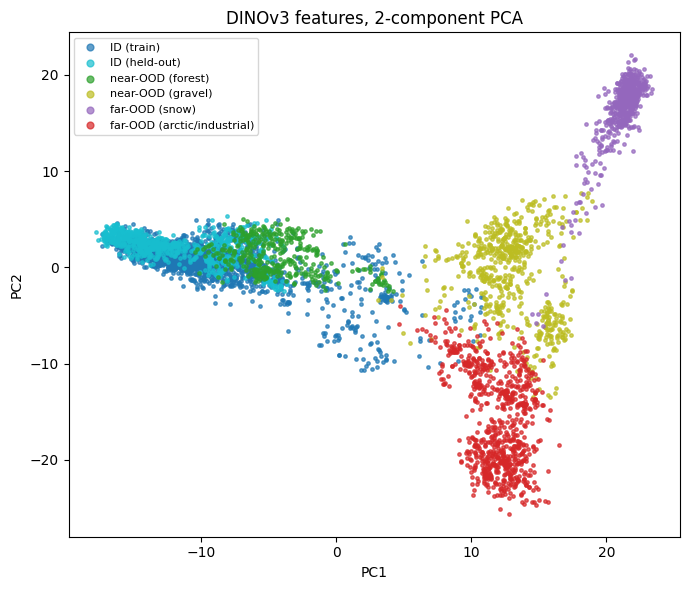

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
for t in TIER_ORDER:
    m = tier == t
    ax.scatter(p2[m, 0], p2[m, 1], s=6, alpha=0.7, color=TIER_COLOR[t], label=TIER_LABEL[t])
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("DINOv3 features, 2-component PCA")
ax.legend(markerscale=2, fontsize=8, loc="best")
plt.tight_layout()
plt.savefig(OUT_DIR / "pca_2d.pdf")
plt.savefig(OUT_DIR / "pca_2d.png", dpi=150)
plt.show()

In [6]:
fig = go.Figure()
for t in TIER_ORDER:
    m = tier == t
    fig.add_trace(go.Scattergl(
        x=p2[m, 0], y=p2[m, 1], mode="markers", name=TIER_LABEL[t],
        marker=dict(size=5, color=TIER_COLOR[t], opacity=0.75),
        text=[f"mission={mm}" for mm in mission[m]], hoverinfo="text+name",
    ))
fig.update_layout(title="DINOv3 features, 2-component PCA", xaxis_title="PC1", yaxis_title="PC2", height=650)
fig.show()

## 3-component PCA

In [7]:
pca3 = PCA(3).fit(Xs)
p3 = pca3.transform(Xs)
print(f"explained variance ratio: {pca3.explained_variance_ratio_}")
sil_pca3 = silhouette_score(p3, tier)
print(f"silhouette(PCA-3d, tier) = {sil_pca3:.3f}")

explained variance ratio: [0.21460482 0.10567466 0.06776723]


silhouette(PCA-3d, tier) = 0.225


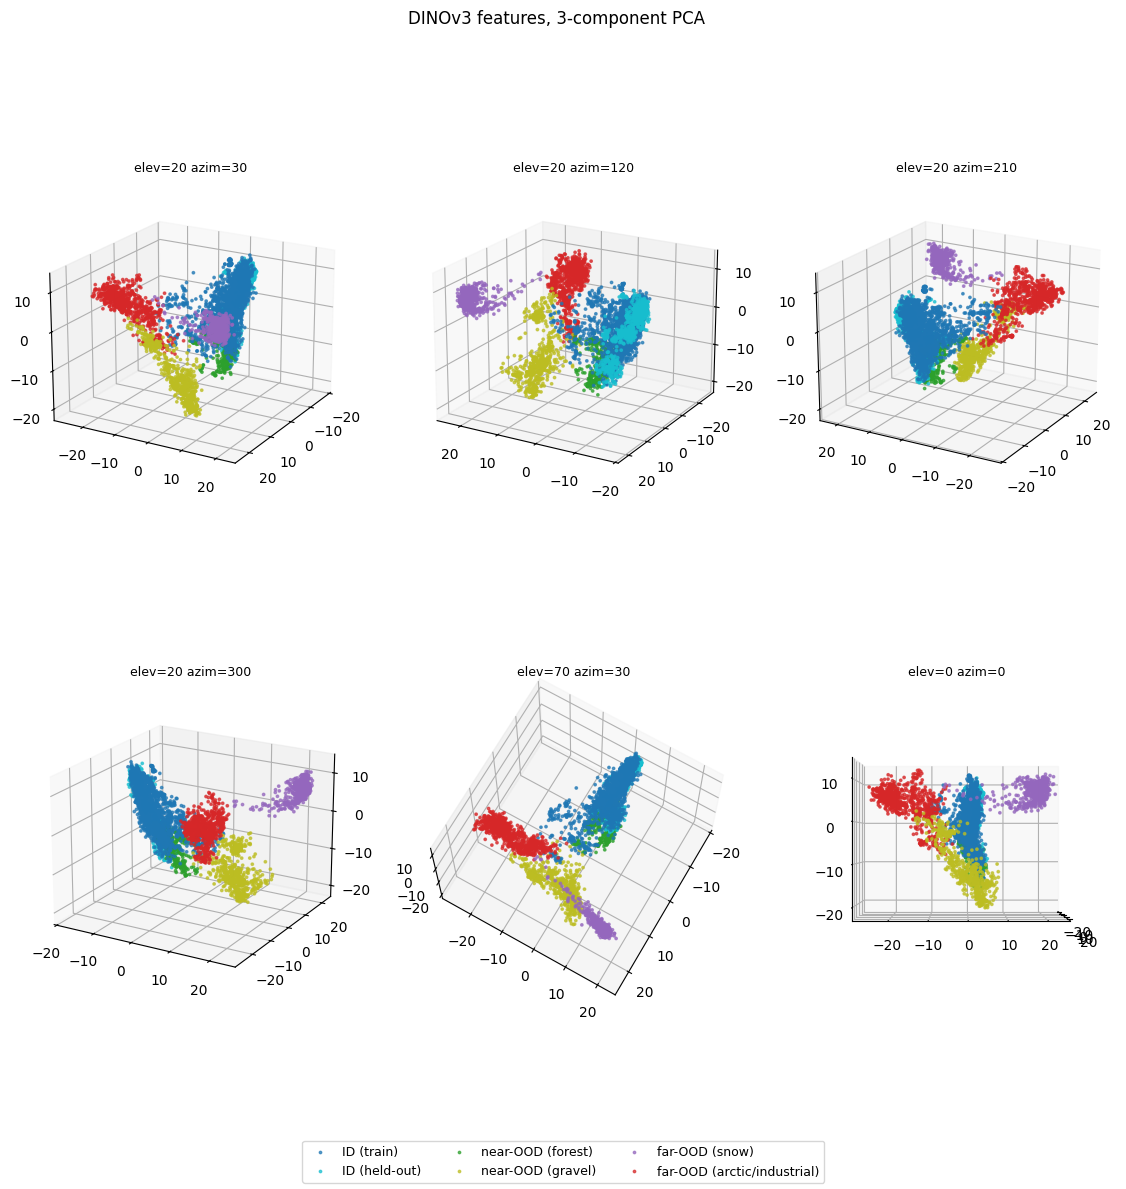

In [8]:
fig = plt.figure(figsize=(14, 12))
for i, (elev, azim) in enumerate([(20, 30), (20, 120), (20, 210), (20, 300), (70, 30), (0, 0)]):
    ax = fig.add_subplot(2, 3, i + 1, projection="3d")
    for t in TIER_ORDER:
        m = tier == t
        ax.scatter(p3[m, 0], p3[m, 1], p3[m, 2], s=3, alpha=0.7, color=TIER_COLOR[t], label=TIER_LABEL[t])
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(f"elev={elev} azim={azim}", fontsize=9)
handles, labels = fig.axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=9)
fig.suptitle("DINOv3 features, 3-component PCA")
plt.savefig(OUT_DIR / "pca_3d.pdf")
plt.savefig(OUT_DIR / "pca_3d.png", dpi=150)
plt.show()

In [9]:
fig = go.Figure()
for t in TIER_ORDER:
    m = tier == t
    fig.add_trace(go.Scatter3d(
        x=p3[m, 0], y=p3[m, 1], z=p3[m, 2], mode="markers", name=TIER_LABEL[t],
        marker=dict(size=3, color=TIER_COLOR[t], opacity=0.75),
        text=[f"mission={mm}" for mm in mission[m]], hoverinfo="text+name",
    ))
fig.update_layout(
    title="DINOv3 features, 3-component PCA",
    scene=dict(xaxis_title="PC1", yaxis_title="PC2", zaxis_title="PC3"),
    height=750,
)
fig.show()

## 3-component PCA, colored by mission

Same PCA embedding as above (`p3`), but colored per individual mission instead
of per tier -- shows whether missions within the same tier (e.g. the 3 far-OOD
ARC runs, or the 10 ID train missions) sit as one blob or split into their own
sub-clusters.

In [10]:
import plotly.express as px

missions_sorted = sorted(set(mission))
palette = (px.colors.qualitative.Dark24 + px.colors.qualitative.Light24)[: len(missions_sorted)]
MISSION_COLOR = dict(zip(missions_sorted, palette))
MISSION_LABEL = {m_name: m_name for m_name in missions_sorted}

fig = go.Figure()
for m_name in missions_sorted:
    m = mission == m_name
    fig.add_trace(go.Scatter3d(
        x=p3[m, 0], y=p3[m, 1], z=p3[m, 2], mode="markers", name=m_name,
        marker=dict(size=3, color=MISSION_COLOR[m_name], opacity=0.75),
        text=[f"mission={m_name} tier={tt}" for tt in tier[m]], hoverinfo="text",
    ))
add_tier_hulls(fig, p3, mission, missions_sorted, MISSION_LABEL, MISSION_COLOR, opacity=0.08)
fig.update_layout(
    title="DINOv3 features, 3-component PCA, colored by mission (with per-mission convex-hull outlines)",
    scene=dict(xaxis_title="PC1", yaxis_title="PC2", zaxis_title="PC3"),
    height=800,
    legend=dict(itemsizing="constant"),
)
fig.show()

## 2-component t-SNE

Nonlinear, preserves local neighborhoods rather than global variance -- often
shows tighter, better-separated clusters than PCA even when the raw-feature
silhouette above is the same, because it is explicitly optimizing for that.

In [11]:
t2 = TSNE(n_components=2, init="pca", perplexity=30, random_state=0).fit_transform(Xs)
sil_tsne2 = silhouette_score(t2, tier)
print(f"silhouette(t-SNE-2d, tier) = {sil_tsne2:.3f}")

silhouette(t-SNE-2d, tier) = 0.174


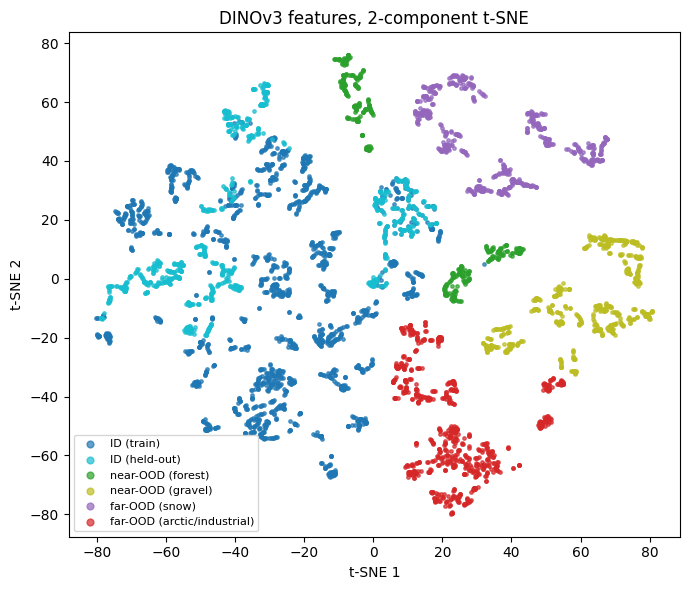

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
for t in TIER_ORDER:
    m = tier == t
    ax.scatter(t2[m, 0], t2[m, 1], s=6, alpha=0.7, color=TIER_COLOR[t], label=TIER_LABEL[t])
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
ax.set_title("DINOv3 features, 2-component t-SNE")
ax.legend(markerscale=2, fontsize=8, loc="best")
plt.tight_layout()
plt.savefig(OUT_DIR / "tsne_2d.pdf")
plt.savefig(OUT_DIR / "tsne_2d.png", dpi=150)
plt.show()

In [13]:
fig = go.Figure()
for t in TIER_ORDER:
    m = tier == t
    fig.add_trace(go.Scattergl(
        x=t2[m, 0], y=t2[m, 1], mode="markers", name=TIER_LABEL[t],
        marker=dict(size=5, color=TIER_COLOR[t], opacity=0.75),
        text=[f"mission={mm}" for mm in mission[m]], hoverinfo="text+name",
    ))
fig.update_layout(title="DINOv3 features, 2-component t-SNE", xaxis_title="t-SNE 1", yaxis_title="t-SNE 2", height=650)
fig.show()

## 3-component t-SNE

In [14]:
t3 = TSNE(n_components=3, init="pca", perplexity=30, random_state=0).fit_transform(Xs)
sil_tsne3 = silhouette_score(t3, tier)
print(f"silhouette(t-SNE-3d, tier) = {sil_tsne3:.3f}")

silhouette(t-SNE-3d, tier) = 0.159


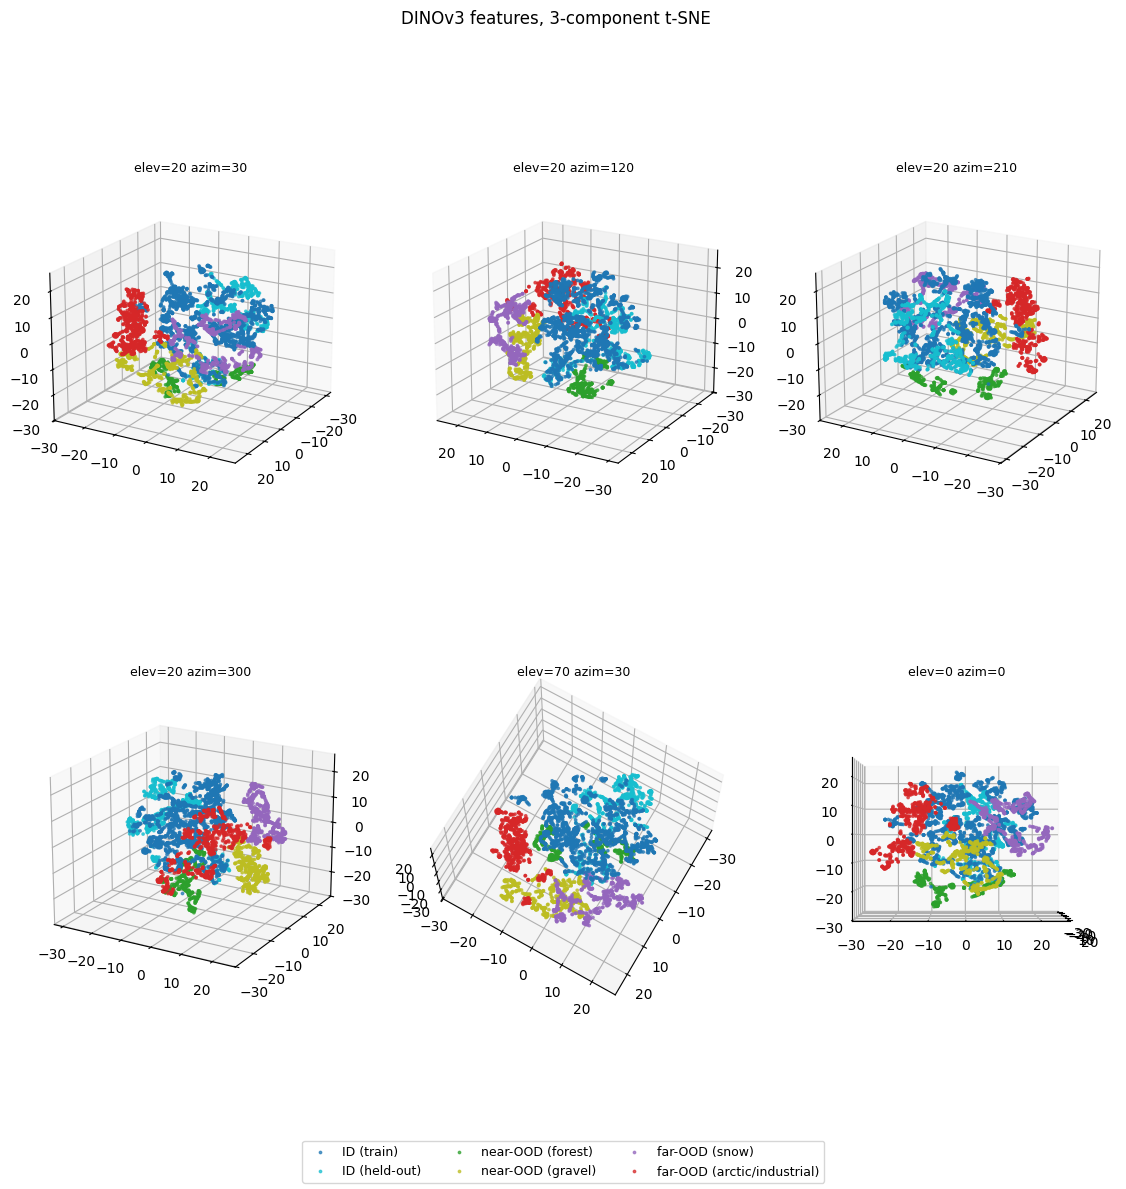

In [15]:
fig = plt.figure(figsize=(14, 12))
for i, (elev, azim) in enumerate([(20, 30), (20, 120), (20, 210), (20, 300), (70, 30), (0, 0)]):
    ax = fig.add_subplot(2, 3, i + 1, projection="3d")
    for t in TIER_ORDER:
        m = tier == t
        ax.scatter(t3[m, 0], t3[m, 1], t3[m, 2], s=3, alpha=0.7, color=TIER_COLOR[t], label=TIER_LABEL[t])
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(f"elev={elev} azim={azim}", fontsize=9)
handles, labels = fig.axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=9)
fig.suptitle("DINOv3 features, 3-component t-SNE")
plt.savefig(OUT_DIR / "tsne_3d.pdf")
plt.savefig(OUT_DIR / "tsne_3d.png", dpi=150)
plt.show()

In [16]:
fig = go.Figure()
for t in TIER_ORDER:
    m = tier == t
    fig.add_trace(go.Scatter3d(
        x=t3[m, 0], y=t3[m, 1], z=t3[m, 2], mode="markers", name=TIER_LABEL[t],
        marker=dict(size=3, color=TIER_COLOR[t], opacity=0.75),
        text=[f"mission={mm}" for mm in mission[m]], hoverinfo="text+name",
    ))
fig.update_layout(
    title="DINOv3 features, 3-component t-SNE",
    scene=dict(xaxis_title="t-SNE 1", yaxis_title="t-SNE 2", zaxis_title="t-SNE 3"),
    height=750,
)
fig.show()

## PCA vs t-SNE: summary

The cell below prints the silhouette scores collected above side by side. Read
them together with the raw 768-d silhouette: if a projection's silhouette is
much higher than the raw one, it is *manufacturing* apparent separation (t-SNE
is well known to do this -- it always finds some clustering, even in noise);
if it is close to or below the raw score, the projection is a faithful 2D/3D
summary of real structure.

In [17]:
print(f"{'projection':<16} {'silhouette':>10}")
print(f"{'raw (768-d)':<16} {sil_raw:>10.3f}")
print(f"{'PCA-2d':<16} {sil_pca2:>10.3f}")
print(f"{'PCA-3d':<16} {sil_pca3:>10.3f}")
print(f"{'t-SNE-2d':<16} {sil_tsne2:>10.3f}")
print(f"{'t-SNE-3d':<16} {sil_tsne3:>10.3f}")

projection       silhouette
raw (768-d)           0.088
PCA-2d                0.197
PCA-3d                0.225
t-SNE-2d              0.174
t-SNE-3d              0.159
